# 🔮 Customer Churn Prediction — End-to-End ML Project
**Uçtan Uca Yapay Zeka Projesi: Veriden Tahmine**

| | |
|---|---|
| **Author** | Hazal |
| **Dataset** | IBM Telco Customer Churn — 7,043 customers, 21 columns |
| **Problem type** | Binary classification (Churn: Yes / No) |
| **Tools** | Python, Pandas, NumPy, Matplotlib, Seaborn, scikit-learn, XGBoost |

This notebook walks through all 7 curriculum stages. Every number shown in the text is **computed live** from the data, so the notebook stays consistent if the data changes.

**Contents**
1. Problem Definition *(Aşama 1)*
2. Data Collection & Cleaning *(Aşama 2)*
3. Exploratory Data Analysis *(Aşama 3)*
4. Model Building & Training *(Aşama 4)*
5. Prediction & Evaluation *(Aşama 5)*
6. Smart Prediction Tool — `tahmin_et()` *(Aşama 6)*
7. Conclusions *(Aşama 7)*

> The production version of this pipeline (modular code, Streamlit app, SHAP, threshold optimisation) lives in `src/` and `app/`.

## 1. Problem Definition *(Aşama 1: Problem Tanımı ve Proje Planı)*

### Project Definition Form *(Proje Tanım Formu)*
| Field | Value |
|---|---|
| **Domain** | Telecommunications / customer retention |
| **Problem statement** | *Predict whether a customer will churn (leave the company) from their demographics, subscribed services and account/billing information.* |
| **Target variable (y)** | `Churn` (Yes → 1, No → 0) |
| **Problem type** | **Classification** (binary) |
| **Features (X)** | 19 original columns + 8 engineered features |

### Why does this matter? *(Gerekçe)*
Acquiring a new customer typically costs several times more than keeping an existing one. If a telecom company can identify which customers are likely to leave **before** they leave, its retention team can contact them with a targeted offer (a contract discount, a free tech-support bundle, an auto-pay incentive). This model is useful for **customer-retention and marketing teams**: it tells them *who* to contact and, through feature analysis, *why* those customers are at risk — so the retention budget is spent where it has the most impact.

## 2. Data Collection & Cleaning *(Aşama 2: Veri Toplama ve Hazırlama)*
### 2.1 Libraries

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
COLORS = {"coral": "#FF6B6B", "teal": "#4ECDC4", "sky": "#45B7D1",
          "sage": "#96CEB4", "plum": "#DDA0DD", "cream": "#FFEAA7"}
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.titleweight": "bold", "axes.titlesize": 14})
print("Libraries loaded. pandas", pd.__version__, "| numpy", np.__version__)

Libraries loaded. pandas 2.2.3 | numpy 2.1.0


### 2.2 Load the CSV with `pd.read_csv`
Works from the repo root, from `notebooks/`, or in Google Colab (downloads the public IBM file if no local copy is found).

In [2]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
candidates = [Path("data/raw/telco_churn.csv"), Path("../data/raw/telco_churn.csv")]
data_path = next((p for p in candidates if p.exists()), None)

df = pd.read_csv(data_path if data_path else DATA_URL)
print("Loaded from:", data_path if data_path else DATA_URL)
print("Shape (rows, columns):", df.shape)
df.head()

Loaded from: ..\data\raw\telco_churn.csv
Shape (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 2.3 Data Dictionary *(Veri Sözlüğü)*

In [3]:
descriptions = {
    "customerID": "Unique customer id (dropped, not a feature)",
    "gender": "Male / Female", "SeniorCitizen": "1 = aged 65+, 0 = otherwise",
    "Partner": "Has a partner (Yes/No)", "Dependents": "Has dependents (Yes/No)",
    "tenure": "Months the customer has stayed", "PhoneService": "Has phone service",
    "MultipleLines": "Has multiple lines", "InternetService": "DSL / Fiber optic / No",
    "OnlineSecurity": "Online security add-on", "OnlineBackup": "Online backup add-on",
    "DeviceProtection": "Device protection add-on", "TechSupport": "Tech support add-on",
    "StreamingTV": "Streams TV", "StreamingMovies": "Streams movies",
    "Contract": "Month-to-month / One year / Two year", "PaperlessBilling": "Paperless billing",
    "PaymentMethod": "Electronic check / Mailed check / Bank transfer / Credit card",
    "MonthlyCharges": "Current monthly bill ($)", "TotalCharges": "Total billed so far ($)",
    "Churn": "TARGET - left in the last month (Yes/No)",
}
data_dict = pd.DataFrame({
    "Column": df.columns,
    "Type": ["numeric" if pd.api.types.is_numeric_dtype(df[c]) else "categorical" for c in df.columns],
    "Unique values": [df[c].nunique() for c in df.columns],
    "Meaning": [descriptions.get(c, "") for c in df.columns],
})
data_dict

,Column,Type,Unique values,Meaning
0,customerID,categorical,7043,"Unique customer id (dropped, not a feature)"
1,gender,categorical,2,Male / Female
2,SeniorCitizen,numeric,2,"1 = aged 65+, 0 = otherwise"
3,Partner,categorical,2,Has a partner (Yes/No)
4,Dependents,categorical,2,Has dependents (Yes/No)
5,tenure,numeric,73,Months the customer has stayed
6,PhoneService,categorical,2,Has phone service
7,MultipleLines,categorical,3,Has multiple lines
8,InternetService,categorical,3,DSL / Fiber optic / No
9,OnlineSecurity,categorical,3,Online security add-on


### 2.4 Detect missing / invalid values (`isnull`)

In [4]:
print("Missing values per column (raw):")
print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().sum().any() else "  none reported by isnull()")
print("\nTotalCharges dtype:", df["TotalCharges"].dtype, "<- should be numeric!")
blank_mask = df["TotalCharges"].astype(str).str.strip() == ""
print("Rows where TotalCharges is a blank string:", blank_mask.sum())
df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Missing values per column (raw):
  none reported by isnull()

TotalCharges dtype: object <- should be numeric!
Rows where TotalCharges is a blank string: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


### 2.5 Cleaning steps *(Temizleme adımları)*
1. **`TotalCharges`** is stored as text because 11 rows contain a blank string. All of them have `tenure = 0` (brand-new customers not yet billed) → convert to numeric and **fill with 0** (`fillna`).
2. **`customerID`** is just an identifier → dropped.
3. **`Churn`** Yes/No → 1/0.

In [5]:
df_clean = df.drop(columns=["customerID"]).copy()
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")
print("NaNs after conversion:", df_clean["TotalCharges"].isnull().sum())
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0.0)
df_clean["Churn"] = (df_clean["Churn"] == "Yes").astype(int)
print("NaNs after fillna:", df_clean.isnull().sum().sum())
print("Clean shape:", df_clean.shape)

NaNs after conversion: 11
NaNs after fillna: 0
Clean shape: (7043, 20)


### 2.6 Feature engineering (extra)
8 domain features that capture price changes, service bundling, protection gaps and customer lifecycle.

In [6]:
services = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def engineer_features(d: pd.DataFrame) -> pd.DataFrame:
    d = d.copy()
    d["AvgMonthlyCharge"] = d["TotalCharges"] / d["tenure"].clip(lower=1)          # historical average bill
    d["PriceDiscrepancy"] = d["MonthlyCharges"] - d["AvgMonthlyCharge"]            # recent price increase?
    d["NumServices"] = sum((d[c] == "Yes").astype(int) for c in services)          # bundle size
    d["UnprotectedInternet"] = (d["InternetService"].isin(["DSL", "Fiber optic"])
                                & (d["TechSupport"] != "Yes") & (d["OnlineSecurity"] != "Yes")).astype(int)
    d["TenureCohort"] = pd.cut(d["tenure"], bins=[-1, 12, 36, np.inf],
                               labels=["New", "Mid-term", "Long-term"], right=False).astype(str)
    d["HasPartnerOrDependents"] = ((d["Partner"] == "Yes") | (d["Dependents"] == "Yes")).astype(int)
    d["ContractScore"] = d["Contract"].map({"Month-to-month": 0, "One year": 1, "Two year": 2}).fillna(0).astype(int)
    d["HasAutoPayment"] = d["PaymentMethod"].str.contains("automatic", case=False).astype(int)
    return d

df_clean = engineer_features(df_clean)
print("Shape after feature engineering:", df_clean.shape)
df_clean[["AvgMonthlyCharge", "PriceDiscrepancy", "NumServices", "UnprotectedInternet",
          "TenureCohort", "HasPartnerOrDependents", "ContractScore", "HasAutoPayment"]].head()

Shape after feature engineering: (7043, 28)


,AvgMonthlyCharge,PriceDiscrepancy,NumServices,UnprotectedInternet,TenureCohort,HasPartnerOrDependents,ContractScore,HasAutoPayment
0,29.850000,0.000000,1,1,New,1,0,0
1,55.573529,1.376471,3,0,Mid-term,0,1,0
2,54.075000,-0.225000,3,0,New,0,0,0
3,40.905556,1.394444,3,0,Long-term,0,1,1
4,75.825000,-5.125000,1,1,New,0,0,0


## 3. Exploratory Data Analysis *(Aşama 3: Keşifçi Veri Analizi)*
### 3.1 Summary statistics — `shape`, `describe()`, `value_counts()`

In [7]:
print("shape:", df_clean.shape)
print("\nTarget distribution (value_counts):")
print(df_clean["Churn"].value_counts().rename({0: "Stayed (0)", 1: "Churned (1)"}))
print(f"\nOverall churn rate: {df_clean['Churn'].mean():.1%}")
df_clean[["tenure", "MonthlyCharges", "TotalCharges", "NumServices"]].describe().round(2)

shape: (7043, 28)

Target distribution (value_counts):
Churn
Stayed (0)     5174
Churned (1)    1869
Name: count, dtype: int64

Overall churn rate: 26.5%


,tenure,MonthlyCharges,TotalCharges,NumServices
count,7043.00,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73,3.36
std,24.56,30.09,2266.79,2.06
min,0.00,18.25,0.00,0.00
25%,9.00,35.50,398.55,1.00
50%,29.00,70.35,1394.55,3.00
75%,55.00,89.85,3786.60,5.00
max,72.00,118.75,8684.80,8.00


### 3.2 Differences by target — `groupby`

In [8]:
for col in ["Contract", "InternetService", "PaymentMethod", "TenureCohort", "UnprotectedInternet"]:
    g = df_clean.groupby(col)["Churn"].agg(customers="count", churn_rate="mean").sort_values("churn_rate", ascending=False)
    g["churn_rate"] = (g["churn_rate"] * 100).round(1).astype(str) + "%"
    print(f"--- Churn by {col} ---\n{g}\n")

--- Churn by Contract ---
                customers churn_rate
Contract                            
Month-to-month       3875      42.7%
One year             1473      11.3%
Two year             1695       2.8%

--- Churn by InternetService ---
                 customers churn_rate
InternetService                      
Fiber optic           3096      41.9%
DSL                   2421      19.0%
No                    1526       7.4%

--- Churn by PaymentMethod ---
                           customers churn_rate
PaymentMethod                                  
Electronic check                2365      45.3%
Mailed check                    1612      19.1%
Bank transfer (automatic)       1544      16.7%
Credit card (automatic)         1522      15.2%

--- Churn by TenureCohort ---
              customers churn_rate
TenureCohort                      
New                2069      48.3%
Mid-term           1923      26.1%
Long-term          3051      12.1%

--- Churn by UnprotectedInternet ---
 

### 3.3 Charts

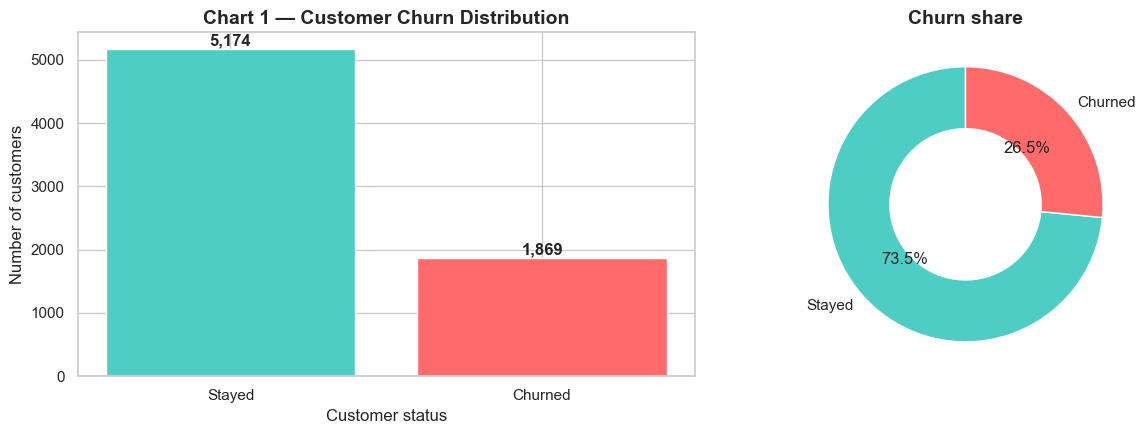

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
counts = df_clean["Churn"].value_counts().sort_index()
bars = ax1.bar(["Stayed", "Churned"], counts.values, color=[COLORS["teal"], COLORS["coral"]])
for b, v in zip(bars, counts.values):
    ax1.text(b.get_x() + b.get_width() / 2, v + 60, f"{v:,}", ha="center", fontweight="bold")
ax1.set_title("Chart 1 — Customer Churn Distribution"); ax1.set_xlabel("Customer status"); ax1.set_ylabel("Number of customers")
ax2.pie(counts.values, labels=["Stayed", "Churned"], autopct="%1.1f%%", startangle=90,
        colors=[COLORS["teal"], COLORS["coral"]], wedgeprops={"width": 0.45})
ax2.set_title("Churn share")
plt.tight_layout(); plt.show()

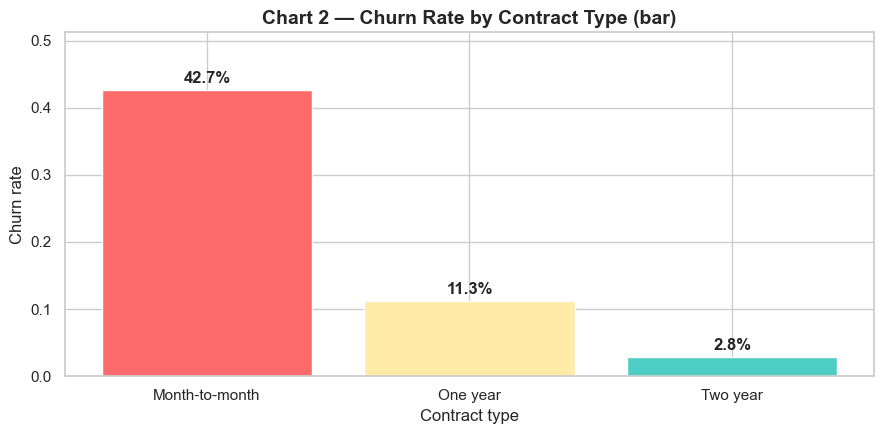

In [10]:
rate = df_clean.groupby("Contract")["Churn"].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(rate.index, rate.values, color=[COLORS["coral"], COLORS["cream"], COLORS["teal"]])
for b, v in zip(bars, rate.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.1%}", ha="center", fontweight="bold")
ax.set_title("Chart 2 — Churn Rate by Contract Type (bar)"); ax.set_xlabel("Contract type"); ax.set_ylabel("Churn rate")
ax.set_ylim(0, rate.max() * 1.2)
plt.tight_layout(); plt.show()

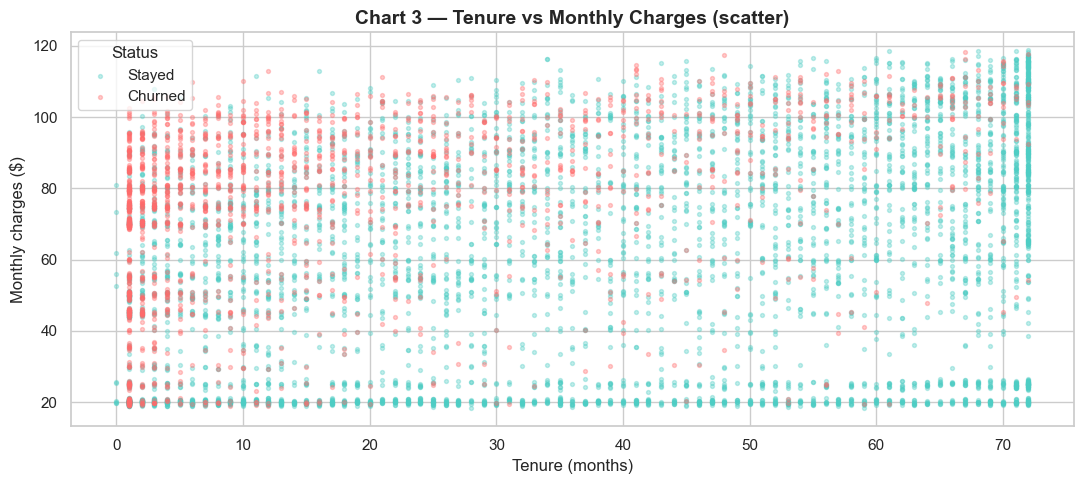

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))
for label, color, name in [(0, COLORS["teal"], "Stayed"), (1, COLORS["coral"], "Churned")]:
    s = df_clean.loc[df_clean["Churn"] == label]
    ax.scatter(s["tenure"], s["MonthlyCharges"], s=8, alpha=0.35, color=color, label=name)
ax.set_title("Chart 3 — Tenure vs Monthly Charges (scatter)")
ax.set_xlabel("Tenure (months)"); ax.set_ylabel("Monthly charges ($)"); ax.legend(title="Status")
plt.tight_layout(); plt.show()

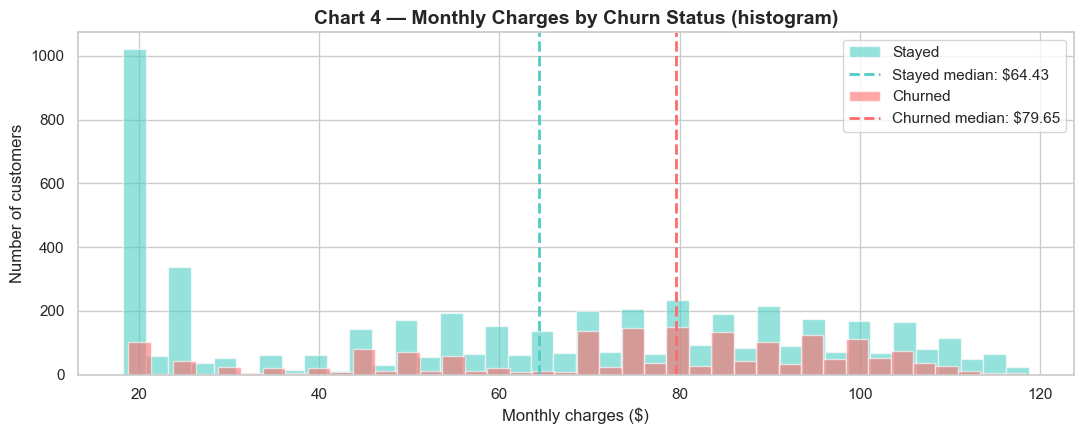

In [12]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for label, color, name in [(0, COLORS["teal"], "Stayed"), (1, COLORS["coral"], "Churned")]:
    s = df_clean.loc[df_clean["Churn"] == label, "MonthlyCharges"]
    ax.hist(s, bins=40, alpha=0.6, color=color, label=name, edgecolor="white")
    ax.axvline(s.median(), color=color, ls="--", lw=2, label=f"{name} median: ${s.median():.2f}")
ax.set_title("Chart 4 — Monthly Charges by Churn Status (histogram)")
ax.set_xlabel("Monthly charges ($)"); ax.set_ylabel("Number of customers"); ax.legend()
plt.tight_layout(); plt.show()

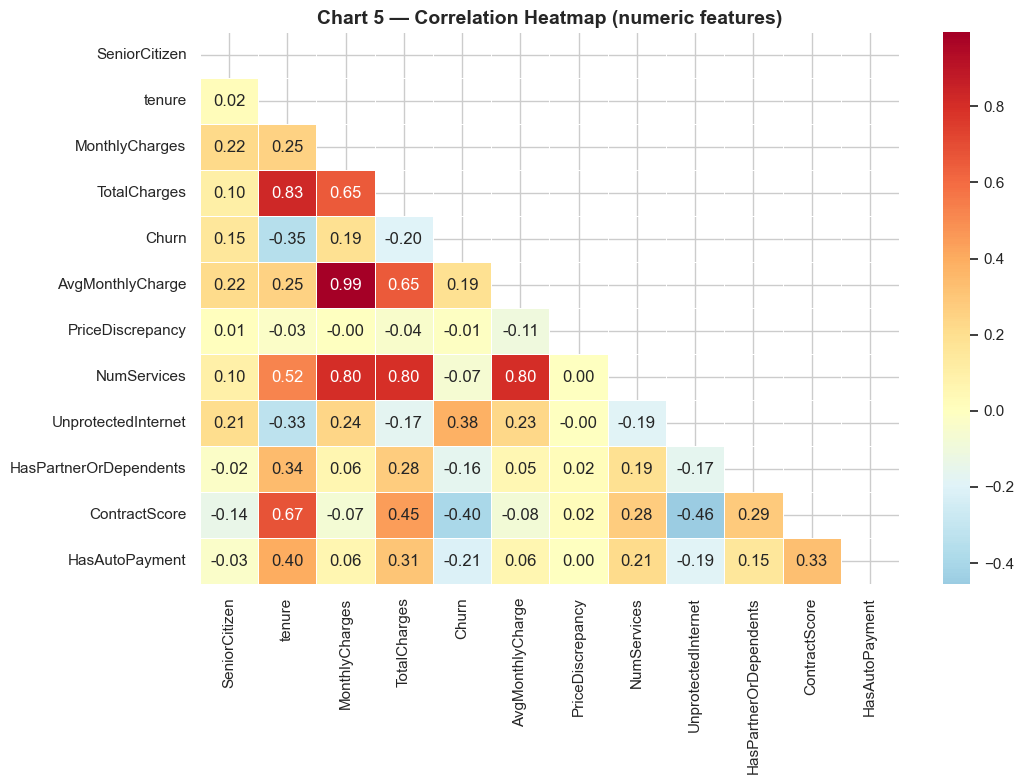

In [13]:
num_cols = df_clean.select_dtypes(include=np.number).columns
corr = df_clean[num_cols].corr()
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt=".2f",
            cmap="RdYlBu_r", center=0, linewidths=0.5, ax=ax)
ax.set_title("Chart 5 — Correlation Heatmap (numeric features)")
plt.tight_layout(); plt.show()

### 3.4 Key findings *(Keşif Bulguları)* — computed from the data

In [14]:
c = df_clean.groupby("Contract")["Churn"].mean()
i = df_clean.groupby("InternetService")["Churn"].mean()
p = df_clean.groupby("PaymentMethod")["Churn"].mean()
u = df_clean.groupby("UnprotectedInternet")["Churn"].mean()
med = df_clean.groupby("Churn")["MonthlyCharges"].median()
early = (df_clean.loc[df_clean["Churn"] == 1, "tenure"] < 12).mean()

findings = [
    f"Contract type is the strongest signal: month-to-month churn is {c['Month-to-month']:.1%}, "
    f"vs {c['One year']:.1%} (1-year) and {c['Two year']:.1%} (2-year).",
    f"New customers are most at risk: {early:.0%} of all churners left within their first 12 months.",
    f"Fiber optic customers churn at {i['Fiber optic']:.1%} vs {i['DSL']:.1%} for DSL — likely a price/value issue.",
    f"Internet users with neither TechSupport nor OnlineSecurity churn at {u[1]:.1%} vs {u[0]:.1%} for everyone else.",
    f"Electronic-check payers churn at {p['Electronic check']:.1%}; automatic payment methods stay around "
    f"{p[['Bank transfer (automatic)', 'Credit card (automatic)']].mean():.1%}.",
    f"Churners pay more per month: median ${med[1]:.2f} vs ${med[0]:.2f} for customers who stayed.",
]
for k, f in enumerate(findings, 1):
    print(f"{k}. {f}")

1. Contract type is the strongest signal: month-to-month churn is 42.7%, vs 11.3% (1-year) and 2.8% (2-year).
2. New customers are most at risk: 53% of all churners left within their first 12 months.
3. Fiber optic customers churn at 41.9% vs 19.0% for DSL — likely a price/value issue.
4. Internet users with neither TechSupport nor OnlineSecurity churn at 49.0% vs 13.8% for everyone else.
5. Electronic-check payers churn at 45.3%; automatic payment methods stay around 16.0%.
6. Churners pay more per month: median $79.65 vs $64.43 for customers who stayed.


## 4. Model Building & Training *(Aşama 4: Model Kurma ve Eğitme)*
### 4.1 Separate features (X) and target (y), then split with `train_test_split`

In [15]:
X = df_clean.drop(columns=["Churn"])
y = df_clean["Churn"]
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Stratified 80/20 split keeps the ~26.5% churn ratio in both sets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

# Scale numeric columns, one-hot encode categorical columns (fit on TRAIN only -> no leakage)
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print("X_train shape:", X_train.shape, "| y_train shape:", y_train.shape)
print("X_test  shape:", X_test.shape, "| y_test  shape:", y_test.shape)
print(f"Churn rate  train: {y_train.mean():.2%} | test: {y_test.mean():.2%}")

X_train shape: (5634, 55) | y_train shape: (5634,)
X_test  shape: (1409, 55) | y_test  shape: (1409,)
Churn rate  train: 26.54% | test: 26.54%


### 4.2 Model choice *(Model seçim gerekçesi)*
This is a **classification** problem, so `LinearRegression` is not appropriate. The curriculum's suggested classifier, **`DecisionTreeClassifier`**, is a good starting point because its decisions are easy to explain (e.g. *"month-to-month AND fiber optic → high risk"*). To be thorough, four more classifiers are compared against it: Logistic Regression (simple, interpretable baseline), Random Forest and XGBoost (tree ensembles, usually strongest on tabular data) and an SVM. Because only ~26.5% of customers churn, models use **class weighting** so they don't just predict "stays" for everyone.

In [16]:
spw = (y_train == 0).sum() / (y_train == 1).sum()   # class-imbalance ratio for XGBoost
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE),
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(eval_metric="logloss", scale_pos_weight=spw, random_state=RANDOM_STATE, n_jobs=-1),
    "SVM": SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE),
}
trained = {}
for name, m in models.items():
    t0 = time.time()
    m.fit(X_train, y_train)            # <- model.fit
    trained[name] = m
    print(f"{name:20s} trained in {time.time() - t0:.2f}s")

Decision Tree        trained in 0.02s
Logistic Regression  trained in 0.01s
Random Forest        trained in 0.14s


XGBoost              trained in 0.19s


SVM                  trained in 3.97s


## 5. Prediction & Evaluation *(Aşama 5: Tahmin ve Değerlendirme)*
### 5.1 Predict on the test set (`model.predict`) and score (`accuracy_score`, `model.score`)

In [17]:
dt = trained["Decision Tree"]
y_pred_dt = dt.predict(X_test)
print(f"Decision Tree accuracy_score: {accuracy_score(y_test, y_pred_dt):.4f}")
print(f"Decision Tree model.score:    {dt.score(X_test, y_test):.4f}")
print(f"Baseline (always predict 'stays'): {(y_test == 0).mean():.4f}  <- accuracy alone can mislead!\n")
print(classification_report(y_test, y_pred_dt, target_names=["Stayed", "Churned"]))

Decision Tree accuracy_score: 0.7551
Decision Tree model.score:    0.7551
Baseline (always predict 'stays'): 0.7346  <- accuracy alone can mislead!

              precision    recall  f1-score   support

      Stayed       0.89      0.76      0.82      1035
     Churned       0.53      0.74      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



### 5.2 Compare all models

In [18]:
def evaluate(models_dict):
    rows = []
    for name, m in models_dict.items():
        pred = m.predict(X_test); proba = m.predict_proba(X_test)[:, 1]
        rows.append({"Model": name,
                     "Train Acc": accuracy_score(y_train, m.predict(X_train)),
                     "Test Acc": accuracy_score(y_test, pred),
                     "Precision": precision_score(y_test, pred),
                     "Recall": recall_score(y_test, pred),
                     "F1": f1_score(y_test, pred),
                     "ROC-AUC": roc_auc_score(y_test, proba)})
    out = pd.DataFrame(rows)
    out["Overfit gap"] = out["Train Acc"] - out["Test Acc"]
    return out.sort_values("F1", ascending=False).round(3).reset_index(drop=True)

results = evaluate(trained)
results

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC,Overfit gap
0,SVM,0.778,0.749,0.518,0.773,0.620,0.824,0.029
1,Decision Tree,0.769,0.755,0.528,0.743,0.617,0.833,0.014
2,Logistic Regression,0.755,0.737,0.503,0.786,0.614,0.843,0.018
3,XGBoost,0.950,0.767,0.549,0.674,0.605,0.822,0.183
4,Random Forest,0.998,0.786,0.625,0.487,0.547,0.824,0.212


**How to read this table**
* **Accuracy** alone is misleading here: always predicting "stays" already gives ~73%.
* **Recall** = share of real churners we catch. **Precision** = share of flagged customers who really churn. **F1** balances both. **ROC-AUC** measures ranking quality independent of the 0.5 cut-off.
* **Overfit gap** = train accuracy − test accuracy. A large gap means the model memorised the training data.

### 5.3 Overfitting check & hyperparameter tuning
The untuned Random Forest (and XGBoost) show a large train/test gap. `GridSearchCV` with 5-fold stratified CV searches for settings that generalise better.

In [19]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={"n_estimators": [100, 200], "max_depth": [5, 8, 12, None], "min_samples_leaf": [1, 5, 10]},
    scoring="f1", cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)
trained["Random Forest (Tuned)"] = grid.best_estimator_
print("Best parameters:", grid.best_params_)
print(f"Best 5-fold CV F1: {grid.best_score_:.3f}")

results = evaluate(trained)
results

Best parameters: {'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 200}
Best 5-fold CV F1: 0.637


,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC,Overfit gap
0,Random Forest (Tuned),0.812,0.764,0.541,0.749,0.628,0.842,0.048
1,SVM,0.778,0.749,0.518,0.773,0.620,0.824,0.029
2,Decision Tree,0.769,0.755,0.528,0.743,0.617,0.833,0.014
3,Logistic Regression,0.755,0.737,0.503,0.786,0.614,0.843,0.018
4,XGBoost,0.950,0.767,0.549,0.674,0.605,0.822,0.183
5,Random Forest,0.998,0.786,0.625,0.487,0.547,0.824,0.212


In [20]:
cv_rows = []
for name, m in trained.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    cv_rows.append({"Model": name, "CV F1 mean": s.mean(), "CV F1 std": s.std()})
cv_table = pd.DataFrame(cv_rows).sort_values("CV F1 mean", ascending=False).round(3).reset_index(drop=True)
best_name = cv_table.iloc[0]["Model"]          # select on CROSS-VALIDATION, not on the test set
best_model = trained[best_name]
print("Selected model (highest CV F1):", best_name)
cv_table

Selected model (highest CV F1): Random Forest (Tuned)


,Model,CV F1 mean,CV F1 std
0,Random Forest (Tuned),0.637,0.014
1,Logistic Regression,0.627,0.025
2,SVM,0.621,0.017
3,Decision Tree,0.613,0.010
4,XGBoost,0.592,0.016
5,Random Forest,0.539,0.016


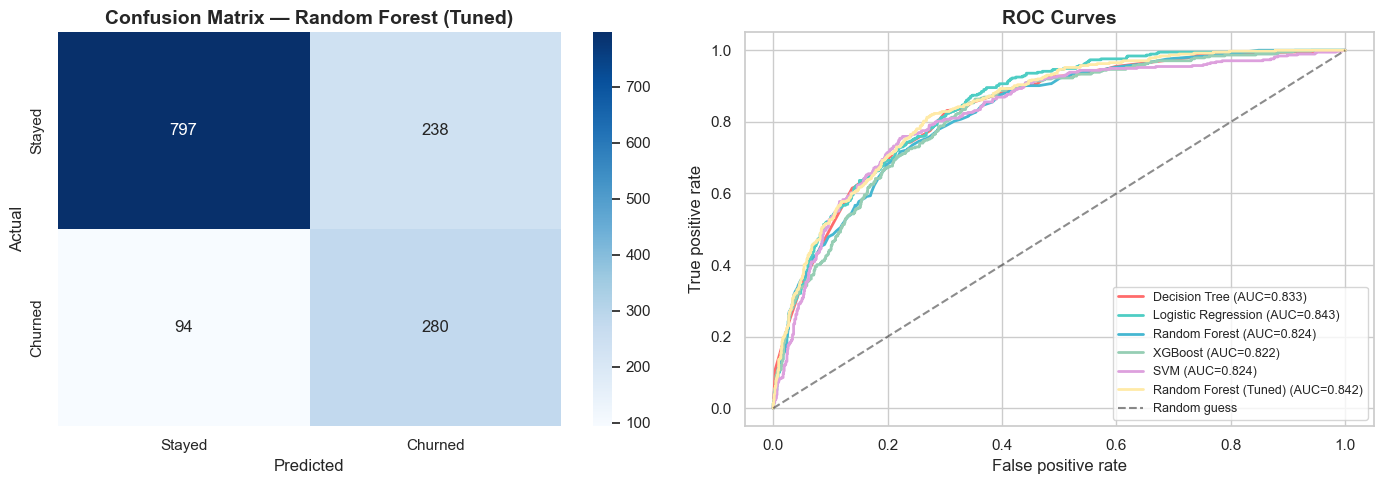

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm = confusion_matrix(y_test, best_model.predict(X_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
axes[0].set_title(f"Confusion Matrix — {best_name}"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

palette = list(COLORS.values()) + ["#2A9D8F"]
for (name, m), col in zip(trained.items(), palette):
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    axes[1].plot(fpr, tpr, color=col, lw=2, label=f"{name} (AUC={roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random guess")
axes[1].set_title("ROC Curves"); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].legend(fontsize=9, loc="lower right")
plt.tight_layout(); plt.show()

### 5.4 Predictions for new customers *(Yeni örnekler için tahmin tablosu)*

In [22]:
new_customers = pd.DataFrame([
    dict(Profile="New fiber customer, month-to-month, e-check", gender="Female", SeniorCitizen=0, Partner="No", Dependents="No",
         tenure=2, PhoneService="Yes", MultipleLines="No", InternetService="Fiber optic", OnlineSecurity="No",
         OnlineBackup="No", DeviceProtection="No", TechSupport="No", StreamingTV="Yes", StreamingMovies="Yes",
         Contract="Month-to-month", PaperlessBilling="Yes", PaymentMethod="Electronic check",
         MonthlyCharges=89.85, TotalCharges=179.70),
    dict(Profile="Loyal family customer, 2-year contract", gender="Male", SeniorCitizen=0, Partner="Yes", Dependents="Yes",
         tenure=68, PhoneService="Yes", MultipleLines="Yes", InternetService="DSL", OnlineSecurity="Yes",
         OnlineBackup="Yes", DeviceProtection="Yes", TechSupport="Yes", StreamingTV="Yes", StreamingMovies="Yes",
         Contract="Two year", PaperlessBilling="No", PaymentMethod="Bank transfer (automatic)",
         MonthlyCharges=84.50, TotalCharges=5746.00),
    dict(Profile="Senior, 5 months, fiber, no support", gender="Male", SeniorCitizen=1, Partner="No", Dependents="No",
         tenure=5, PhoneService="Yes", MultipleLines="Yes", InternetService="Fiber optic", OnlineSecurity="No",
         OnlineBackup="No", DeviceProtection="No", TechSupport="No", StreamingTV="No", StreamingMovies="Yes",
         Contract="Month-to-month", PaperlessBilling="Yes", PaymentMethod="Electronic check",
         MonthlyCharges=85.50, TotalCharges=427.50),
    dict(Profile="Phone-only, 1-year contract", gender="Female", SeniorCitizen=0, Partner="No", Dependents="No",
         tenure=12, PhoneService="Yes", MultipleLines="No", InternetService="No", OnlineSecurity="No internet service",
         OnlineBackup="No internet service", DeviceProtection="No internet service", TechSupport="No internet service",
         StreamingTV="No internet service", StreamingMovies="No internet service", Contract="One year",
         PaperlessBilling="No", PaymentMethod="Mailed check", MonthlyCharges=20.15, TotalCharges=241.80),
])
X_new = preprocessor.transform(engineer_features(new_customers.drop(columns=["Profile"])))
proba_new = best_model.predict_proba(X_new)[:, 1]
pd.DataFrame({
    "Customer (input)": new_customers["Profile"],
    "Prediction": np.where(proba_new >= 0.5, "Will churn", "Will stay"),
    "Churn probability": [f"{p:.1%}" for p in proba_new],
    "Risk": pd.cut(proba_new, [-0.01, 0.35, 0.65, 1.0], labels=["Low", "Medium", "High"]),
})

,Customer (input),Prediction,Churn probability,Risk
0,"New fiber customer, month-to-month, e-check",Will churn,90.1%,High
1,"Loyal family customer, 2-year contract",Will stay,2.1%,Low
2,"Senior, 5 months, fiber, no support",Will churn,90.5%,High
3,"Phone-only, 1-year contract",Will stay,3.2%,Low


**Interpretation:** the model's outputs line up with the EDA findings — short tenure + month-to-month contract + fiber without support + electronic check gives the highest risk, while long-tenure customers on 2-year contracts with automatic payment are rated low-risk.

### 5.5 Evaluation note *(Değerlendirme Notu)* — is the model reliable?

In [23]:
r = results.set_index("Model")
best = r.loc[best_name]
rf_raw = r.loc["Random Forest"]
print(f"Selected model: {best_name}")
print(f"  Test accuracy {best['Test Acc']:.1%} | recall {best['Recall']:.1%} | precision {best['Precision']:.1%} | ROC-AUC {best['ROC-AUC']:.3f}")
print(f"  Train/test accuracy gap: {best['Overfit gap']:+.1%}")
print(f"\nOverfitting example: the untuned Random Forest scores {rf_raw['Train Acc']:.1%} on training data "
      f"but {rf_raw['Test Acc']:.1%} on the test set (gap {rf_raw['Overfit gap']:+.1%}) -> it memorised the training set.")

Selected model: Random Forest (Tuned)
  Test accuracy 76.4% | recall 74.9% | precision 54.1% | ROC-AUC 0.842
  Train/test accuracy gap: +4.8%

Overfitting example: the untuned Random Forest scores 99.8% on training data but 78.6% on the test set (gap +21.2%) -> it memorised the training set.


**Assessment**
* **Reasonably reliable for ranking customers by risk:** ROC-AUC ≈ 0.84 and consistent 5-fold CV scores (low std) show it generalises to unseen customers.
* **Overfitting was a real risk** for the tree ensembles. It was detected with the train/test gap and reduced with depth/leaf-size limits found by `GridSearchCV`. The final model was chosen on cross-validation, and the test set was used only for the final check.
* **Weaknesses:** precision is moderate (roughly half of flagged customers actually churn), so some retention offers will go to customers who would have stayed. The data is a single snapshot (no usage history, complaints or call logs), and the dataset is fictional/US-based, so results may not transfer directly to other markets.
* **Possible improvements:** tune the decision threshold to the business cost of a missed churner vs. an unnecessary offer (implemented in `src/model.py`), add behavioural features, try probability calibration, and retrain regularly on fresh data.

## 6. Smart Prediction Tool *(Aşama 6: Akıllı Tahmin Aracı)*
`tahmin_et()` asks for customer details with `input()`, predicts instantly and prints a meaningful sentence with an f-string.

> Set `INTERAKTIF = True` to type your own answers (in Colab / Jupyter). With `False` the default answers are used automatically so the notebook can run end-to-end. A web version of this tool is in `app/streamlit_app.py`.

In [24]:
INTERAKTIF = False   # True -> answer the questions yourself


def sor(soru, varsayilan, secenekler=None):
    """Ask a question with input(); fall back to the default on empty / invalid input."""
    if not INTERAKTIF:
        print(f"{soru} [{varsayilan}]: {varsayilan}")
        return varsayilan
    cevap = input(f"{soru} [{varsayilan}]: ").strip() or varsayilan
    if secenekler and cevap not in secenekler:
        print(f"  -> Geçersiz seçim, varsayılan kullanılıyor: {varsayilan}")
        return varsayilan
    return cevap


def tahmin_et(model=None):
    """Interactive churn prediction: input -> prediction -> meaningful sentence."""
    model = model or best_model
    print("=" * 60 + "\n  MÜŞTERİ TERK TAHMİN ARACI\n" + "=" * 60)
    tenure = int(sor("Kaç aydır müşteri? (0-72)", "4"))
    sozlesme = sor("Sözleşme tipi (Month-to-month / One year / Two year)", "Month-to-month",
                   ["Month-to-month", "One year", "Two year"])
    internet = sor("İnternet türü (DSL / Fiber optic / No)", "Fiber optic", ["DSL", "Fiber optic", "No"])
    destek = sor("Teknik destek paketi var mı? (Yes / No)", "No", ["Yes", "No"])
    guvenlik = sor("Online güvenlik paketi var mı? (Yes / No)", "No", ["Yes", "No"])
    odeme = sor("Ödeme yöntemi (Electronic check / Mailed check / Bank transfer (automatic) / Credit card (automatic))",
                "Electronic check",
                ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"])
    aylik = float(sor("Aylık fatura ($)", "90"))

    no_net = internet == "No"
    musteri = pd.DataFrame([dict(
        gender="Female", SeniorCitizen=0, Partner="No", Dependents="No", tenure=tenure,
        PhoneService="Yes", MultipleLines="No", InternetService=internet,
        OnlineSecurity="No internet service" if no_net else guvenlik,
        OnlineBackup="No internet service" if no_net else "No",
        DeviceProtection="No internet service" if no_net else "No",
        TechSupport="No internet service" if no_net else destek,
        StreamingTV="No internet service" if no_net else "No",
        StreamingMovies="No internet service" if no_net else "No",
        Contract=sozlesme, PaperlessBilling="Yes", PaymentMethod=odeme,
        MonthlyCharges=aylik, TotalCharges=aylik * tenure)])

    olasilik = model.predict_proba(preprocessor.transform(engineer_features(musteri)))[0, 1]
    risk = "YÜKSEK" if olasilik >= 0.65 else ("ORTA" if olasilik >= 0.35 else "DÜŞÜK")
    karar = "ayrılması bekleniyor" if olasilik >= 0.5 else "kalması bekleniyor"

    print("-" * 60)
    print(f"Sonuç: Bu müşterinin {karar}. Terk olasılığı %{olasilik * 100:.1f} (risk: {risk}).")
    if olasilik >= 0.5:
        oneriler = []
        if sozlesme == "Month-to-month": oneriler.append("yıllık sözleşmeye geçiş için indirim")
        if not no_net and destek == "No": oneriler.append("ücretsiz teknik destek paketi")
        if odeme == "Electronic check": oneriler.append("otomatik ödemeye geçiş teşviki")
        print(f"Öneri: Müşteriyle iletişime geçip {', '.join(oneriler) or 'kişisel bir teklif'} sunun.")
    else:
        print("Öneri: Müşteri memnun görünüyor; ek hizmet (upsell) teklifleri değerlendirilebilir.")
    print("=" * 60)
    return olasilik


_ = tahmin_et()

  MÜŞTERİ TERK TAHMİN ARACI
Kaç aydır müşteri? (0-72) [4]: 4
Sözleşme tipi (Month-to-month / One year / Two year) [Month-to-month]: Month-to-month
İnternet türü (DSL / Fiber optic / No) [Fiber optic]: Fiber optic
Teknik destek paketi var mı? (Yes / No) [No]: No
Online güvenlik paketi var mı? (Yes / No) [No]: No
Ödeme yöntemi (Electronic check / Mailed check / Bank transfer (automatic) / Credit card (automatic)) [Electronic check]: Electronic check
Aylık fatura ($) [90]: 90
------------------------------------------------------------
Sonuç: Bu müşterinin ayrılması bekleniyor. Terk olasılığı %87.1 (risk: YÜKSEK).
Öneri: Müşteriyle iletişime geçip yıllık sözleşmeye geçiş için indirim, ücretsiz teknik destek paketi, otomatik ödemeye geçiş teşviki sunun.


## 7. Conclusions *(Aşama 7: Sonuç ve Çıkarımlar)*

In [25]:
print(f"Final model: {best_name}")
print(f"Test ROC-AUC {best['ROC-AUC']:.3f} | F1 {best['F1']:.3f} | Recall {best['Recall']:.1%} | Precision {best['Precision']:.1%}")
print("\nTop churn drivers (from EDA):")
for f in findings[:5]:
    print(" -", f)

Final model: Random Forest (Tuned)
Test ROC-AUC 0.842 | F1 0.628 | Recall 74.9% | Precision 54.1%

Top churn drivers (from EDA):
 - Contract type is the strongest signal: month-to-month churn is 42.7%, vs 11.3% (1-year) and 2.8% (2-year).
 - New customers are most at risk: 53% of all churners left within their first 12 months.
 - Fiber optic customers churn at 41.9% vs 19.0% for DSL — likely a price/value issue.
 - Internet users with neither TechSupport nor OnlineSecurity churn at 49.0% vs 13.8% for everyone else.
 - Electronic-check payers churn at 45.3%; automatic payment methods stay around 16.0%.


**Business recommendations**
1. Offer month-to-month customers an incentive to switch to an annual contract, especially in their first year.
2. Bundle TechSupport + OnlineSecurity for fiber-optic customers who have neither.
3. Encourage electronic-check payers to move to automatic payment.
4. Use the model's risk score to prioritise the retention team's call list.

**What I learned:** cleaning a real (messy) column, why accuracy is misleading on imbalanced data, how to detect and reduce overfitting, and how to turn a model into a tool a non-technical user can run.

*Project built for the "Uçtan Uca Yapay Zeka Projesi: Veriden Tahmine" programme.*